# LAB5 - PCA of land-cover patches and autoencoder super-resolution

This notebook has two parts. The first one takes small patches of three land-cover types (forest, man-made and ocean), reduces each patch to three numbers with PCA and checks whether patches of the same type end up close to each other. The second one trains a convolutional autoencoder to double the resolution of a satellite image and checks honestly whether the result is better than plain interpolation.

The data are crops of the Sentinel-2 cloudless mosaic (EOX, 2020, true-colour RGB at roughly 10 m per pixel) - the same source as in previous labs. Ojców National Park for the forest, the centre of Kraków gives the man-made class and the open water of the Gulf of Gdańsk gives the water. Two more crops are used only in the second part: the area around Wieliczka as extra training material and western Kraków with Las Wolski as the test image. The files are in `data/` and can be downloaded aas previously by `download_data.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image

from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
from skimage.metrics import structural_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F

def load(name):
    return Image.open(f"data/{name}.jpg").convert("RGB")

scenes = {name: load(name) for name in ["forest", "urban", "ocean", "mixed", "test_scene"]}
for name, img in scenes.items():
    print(f"{name:10s} {img.size[0]} x {img.size[1]} px")

forest     641 x 608 px
urban      572 x 498 px
ocean      776 x 774 px
mixed      859 x 774 px
test_scene 1001 x 774 px


## 1. PCA of land-cover patches

### 1.1 Patches

A patch is an 8 x 8 pixel square of the image, which is 80 m on the ground. With three colour channels it is described by 192 numbers, so every patch is a point in a 192-dimensional space. That space cannot be plotted, and this is the reason for using PCA.

The forest and urban crops are not pure, so the patches are cut only from hand-picked rectangles (row0, row1, col0, col1), the same ones that were used as training areas in previous labs. The ocean crop is open water everywhere, so two arbitrary squares are enough. The rectangles are cut into non-overlapping patches and 500 patches per class are drawn at random, so no class dominates the PCA just because its rectangles are bigger.

forest    629 patches available, 500 used
urban     520 patches available, 500 used
ocean    1250 patches available, 500 used
data matrix: (1500, 192)


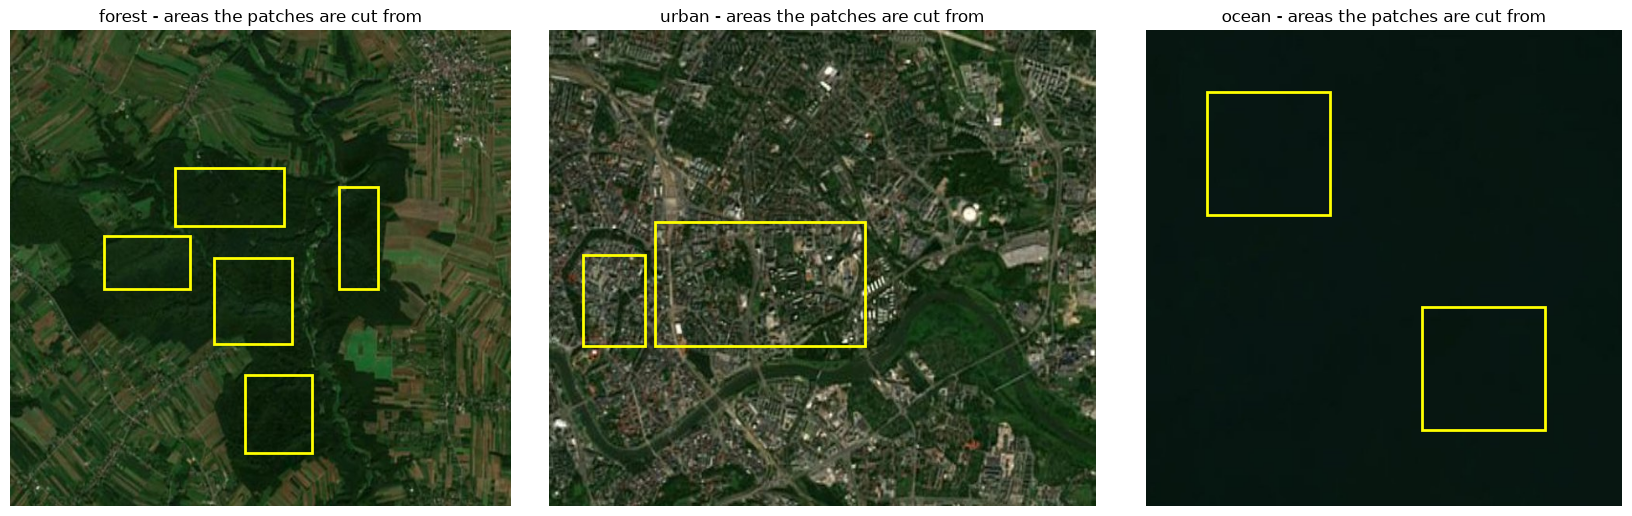

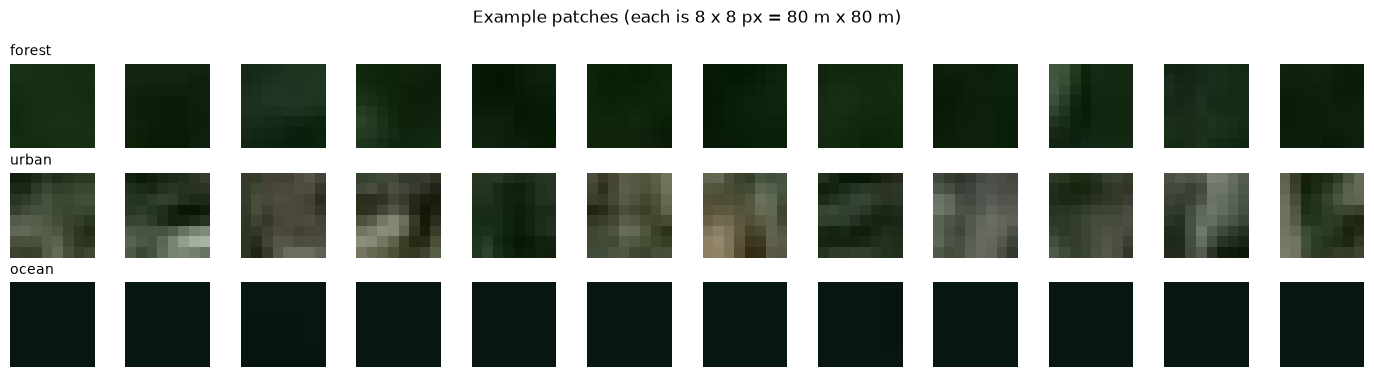

In [2]:
P = 8                    # patch side in pixels
N_PER_CLASS = 500
CLASSES = ["forest", "urban", "ocean"]
COLORS  = {"forest": "tab:green", "urban": "tab:red", "ocean": "tab:blue"}
BOXES = {
    "forest": [(175, 250, 210, 350), (262, 330, 120, 230), (290, 400, 260, 360), (440, 540, 300, 385), (200, 330, 420, 470)],
    "urban":  [(235, 330, 35, 100), (200, 330, 110, 330)],
    "ocean":  [(100, 300, 100, 300), (450, 650, 450, 650)],
}

def cut_patches(img, boxes, p):
    # all non-overlapping p x p patches that fit inside the rectangles, flattened to rows
    a = np.asarray(img).astype(np.float64)
    out = [a[r:r + p, c:c + p].ravel()
           for r0, r1, c0, c1 in boxes
           for r in range(r0, r1 - p + 1, p)
           for c in range(c0, c1 - p + 1, p)]
    return np.array(out)

rng = np.random.default_rng(0)
X, y = [], []
for label, name in enumerate(CLASSES):
    patches = cut_patches(scenes[name], BOXES[name], P)
    keep = rng.choice(len(patches), N_PER_CLASS, replace=False)
    print(f"{name:7s} {len(patches):5d} patches available, {N_PER_CLASS} used")
    X.append(patches[keep]); y += [label] * N_PER_CLASS
X = np.vstack(X); y = np.array(y)
print("data matrix:", X.shape)

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
for ax, name in zip(axes, CLASSES):
    ax.imshow(scenes[name])
    for r0, r1, c0, c1 in BOXES[name]:
        ax.add_patch(Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, ec="yellow", lw=2))
    ax.set_title(f"{name} - areas the patches are cut from"); ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(3, 12, figsize=(14, 3.8))
for row, name in enumerate(CLASSES):
    for col in range(12):
        axes[row, col].imshow(X[y == row][col].reshape(P, P, 3).astype(np.uint8)); axes[row, col].axis("off")
    axes[row, 0].set_title(name, loc="left", fontsize=10)
fig.suptitle("Example patches (each is 8 x 8 px = 80 m x 80 m)"); plt.tight_layout(); plt.show()

### 1.2 Reducing 192 dimensions to 3

PCA looks for the directions in the 192-dimensional space along which the patches differ the most. The first principal component is the direction with the largest variance, the second is the direction with the largest remaining variance that is perpendicular to the first, and so on. Projecting a patch on the first three directions gives three coordinates (PC1, PC2, PC3), and this is the reduced description of the patch. PCA never sees the class labels, so if the classes separate in the plot, it is because the patches themselves are different, not because the method was told what to look for.

The pixel values are only centred (the mean patch is subtracted, `PCA` does it by itself). They are not rescaled, because all 192 features are grey levels on the same 0 to 255 scale and the differences in their spread are real information.

variance explained by PC1, PC2, PC3: [74.1  5.5  4.5] %
together: 84.2 %
correlation between PC1 and the mean brightness of a patch: 0.9999


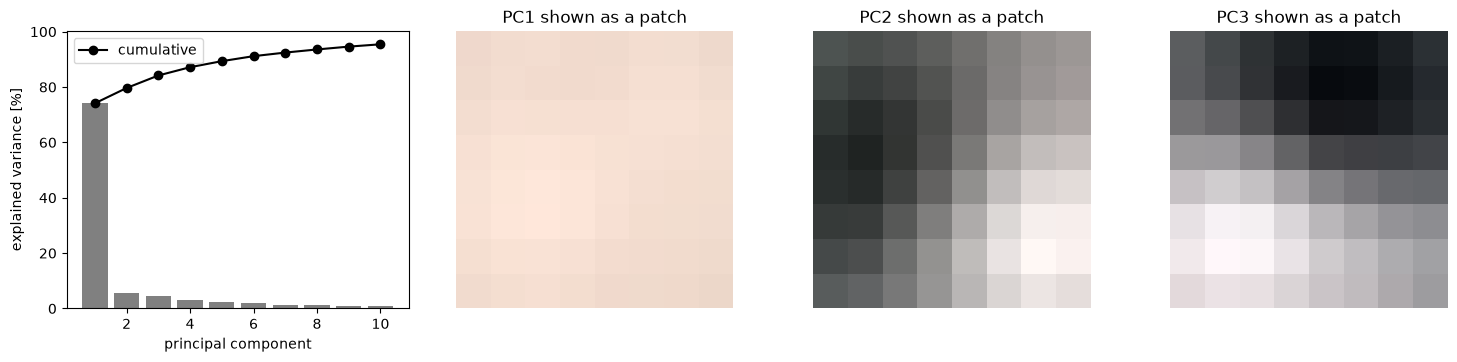

In [3]:
pca_full = PCA().fit(X)
pca = PCA(n_components=3).fit(X)
Z = pca.transform(X)                      # (1500, 3) - the patches in PC coordinates

evr = pca_full.explained_variance_ratio_
print("variance explained by PC1, PC2, PC3:", np.round(100 * evr[:3], 1), "%")
print(f"together: {100 * evr[:3].sum():.1f} %")
print(f"correlation between PC1 and the mean brightness of a patch: {np.corrcoef(Z[:, 0], X.mean(axis=1))[0, 1]:.4f}")

fig = plt.figure(figsize=(15, 3.6))
ax = fig.add_subplot(1, 4, 1)
ax.bar(np.arange(1, 11), 100 * evr[:10], color="gray")
ax.plot(np.arange(1, 11), 100 * np.cumsum(evr[:10]), "o-", color="black", label="cumulative")
ax.set_xlabel("principal component"); ax.set_ylabel("explained variance [%]"); ax.legend()
for i in range(3):
    ax = fig.add_subplot(1, 4, i + 2)
    comp = pca.components_[i].reshape(P, P, 3)
    ax.imshow(0.5 + 0.5 * comp / np.abs(comp).max())      # grey = 0, brighter/darker = positive/negative weight
    ax.set_title(f"PC{i + 1} shown as a patch"); ax.axis("off")
plt.tight_layout(); plt.show()

The first component alone carries 74.1% of the variance, and the first three together 84.2%, so little is lost for plotting purposes. Showing the components as patches explains what they measure. PC1 has almost the same weight on every pixel, which makes it the overall brightness of the patch: its correlation with the mean pixel value is 0.9999. The weights are slightly larger for red than for blue, which gives the component its pinkish tint, because red is the channel in which the three land covers differ the most. PC2 and PC3 are brightness ramps across the patch, one roughly left to right and one top to bottom. They respond to an edge or a gradient inside the patch, in other words to texture, and their sign only says on which side the brighter part is.

The three axes of the plot below mean: how bright the patch is, and how strongly its brightness changes horizontally and vertically.

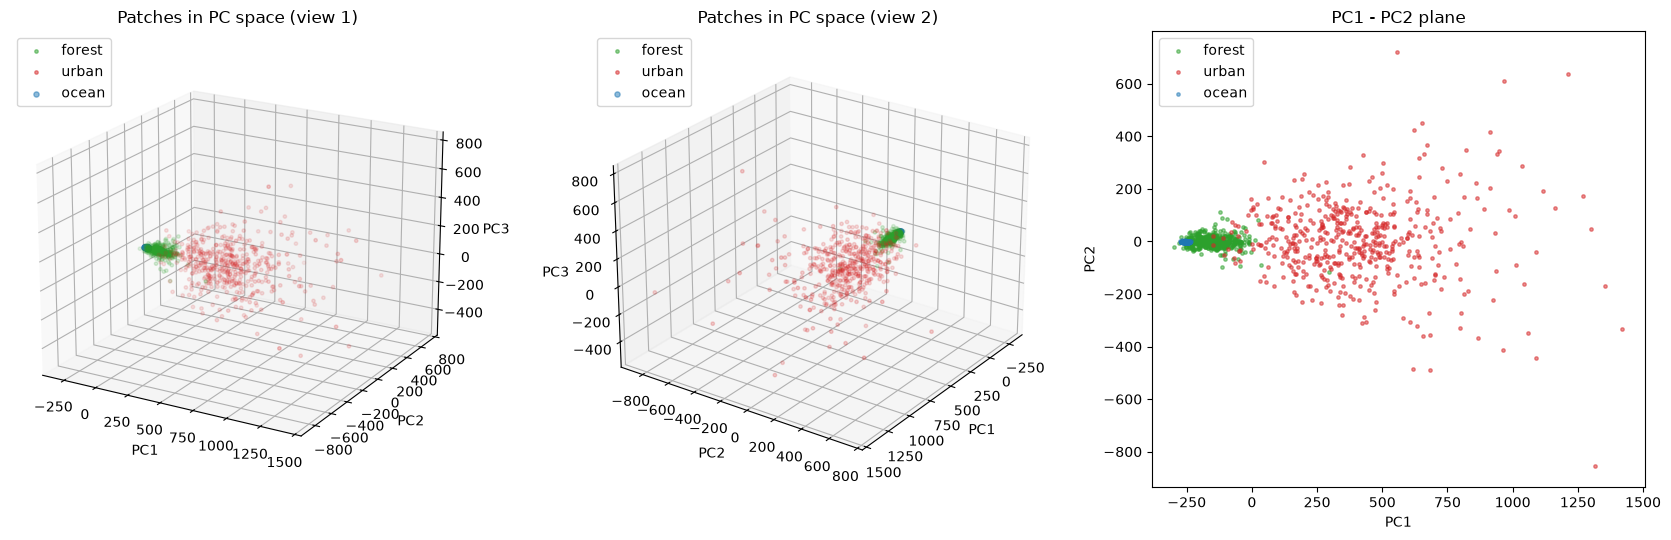

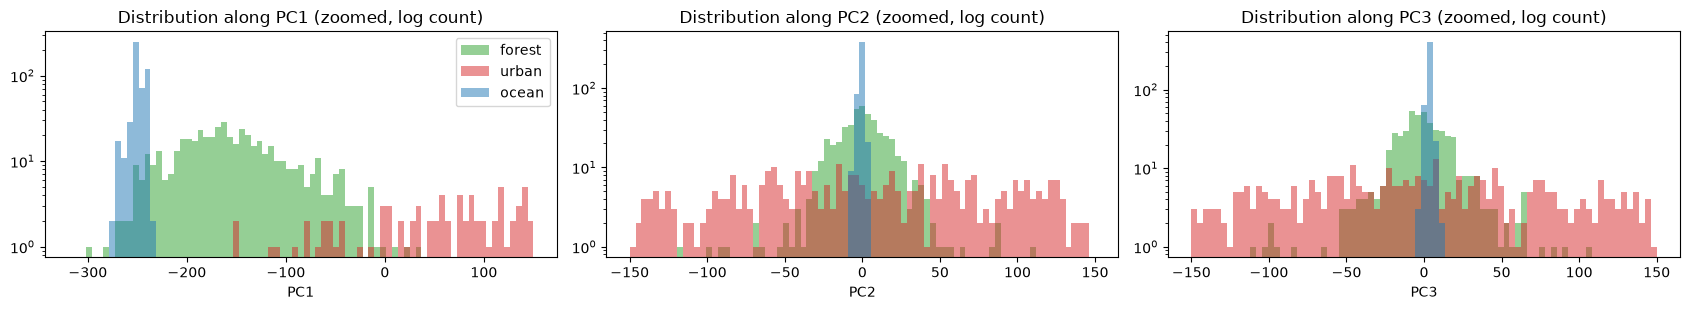

In [4]:
fig = plt.figure(figsize=(17, 5.5))
for i, (elev, azim) in enumerate([(20, -60), (25, 35)]):
    ax = fig.add_subplot(1, 3, i + 1, projection="3d")
    for label, name in enumerate(CLASSES):
        ax.scatter(*Z[y == label].T, s=6 if name != "ocean" else 14, alpha=0.5, color=COLORS[name], label=name)
    ax.view_init(elev, azim)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3"); ax.set_title(f"Patches in PC space (view {i + 1})")
    ax.legend(loc="upper left")
ax = fig.add_subplot(1, 3, 3)
for label, name in enumerate(CLASSES):
    ax.scatter(Z[y == label, 0], Z[y == label, 1], s=6, alpha=0.5, color=COLORS[name], label=name)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("PC1 - PC2 plane"); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 3.2))
for i, ax in enumerate(axes):
    lo, hi = (-320, 150) if i == 0 else (-150, 150)
    for label, name in enumerate(CLASSES):
        ax.hist(Z[y == label, i], bins=np.linspace(lo, hi, 80), alpha=0.5, color=COLORS[name], label=name)
    ax.set_yscale("log"); ax.set_xlabel(f"PC{i + 1}"); ax.set_title(f"Distribution along PC{i + 1} (zoomed, log count)")
axes[0].legend(); plt.tight_layout(); plt.show()

### 1.3 Do the classes cluster?

The plots suggest an answer, and the cell below puts numbers on it in three ways. The first is the position and the spread of each class along the three components. The second is k-means with three clusters run on the PC coordinates without the labels, to see whether an algorithm that knows nothing about the classes would find the same three groups. The third is a 5-nearest-neighbour classifier evaluated with 5-fold cross-validation, which answers a slightly different question: whether a patch is surrounded mostly by patches of its own class.

In [5]:
print("class      mean (PC1, PC2, PC3)          std (PC1, PC2, PC3)")
for label, name in enumerate(CLASSES):
    m, s = Z[y == label].mean(axis=0), Z[y == label].std(axis=0)
    print(f"{name:7s}  {m[0]:8.1f} {m[1]:6.1f} {m[2]:6.1f}       {s[0]:7.1f} {s[1]:6.1f} {s[2]:6.1f}")

clusters = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)
table = np.array([[np.sum((y == t) & (clusters == k)) for k in range(3)] for t in range(3)])
print("\nk-means on the PC coordinates (rows: true class, columns: cluster found)")
for name, row in zip(CLASSES, table):
    print(f"{name:7s} {row}")

knn = KNeighborsClassifier(n_neighbors=5)
acc3 = cross_val_score(knn, Z, y, cv=5).mean()
acc1 = cross_val_score(knn, Z[:, :1], y, cv=5).mean()
acc_full = cross_val_score(knn, X, y, cv=5).mean()
print(f"\n5-NN accuracy, 5-fold CV:  PC1 only {100*acc1:.1f} % | PC1-PC3 {100*acc3:.1f} % | all 192 pixel values {100*acc_full:.1f} %")

class      mean (PC1, PC2, PC3)          std (PC1, PC2, PC3)
forest     -151.9   -0.2   -0.9          61.5   21.7   24.9
urban       401.0    1.8   -2.1         261.8  152.6  137.0
ocean      -249.1   -1.6    3.0           6.6    1.5    1.5

k-means on the PC coordinates (rows: true class, columns: cluster found)
forest  [  0 499   1]
urban   [130  38 332]
ocean   [  0 500   0]

5-NN accuracy, 5-fold CV:  PC1 only 96.1 % | PC1-PC3 97.1 % | all 192 pixel values 97.9 %


### 1.4 Discussion

The patches do cluster by land cover, but the three clusters look nothing alike. Ocean is a single tight point at the dark end of PC1, with a spread of only 6.6 along PC1 and 1.5 along the other two axes, because open water is dark and has no texture at all at 10 m. Forest sits right next to it, a little brighter and about ten times wider. Urban patches are spread over a huge cloud that extends towards high brightness and far in both directions of PC2 and PC3, since a block of 80 m in a city can contain roofs, streets, trees and shadows in any arrangement.

The separation happens almost entirely along PC1. On PC2 and PC3 all three classes are centred on zero, because an edge is as likely to be bright on the left as on the right. What differs there is the spread, not the position: the classes are told apart by how far from zero their patches reach. This is why the second and third component add little to the classification (96.1 % with PC1 alone, 97.1 % with all three), and why three numbers do almost as well as the full 192 pixel values (97.9 %). The patches that are confused are dark urban patches, such as parks and tree-lined streets, which really do look like forest, and the darkest forest patches that touch the ocean cluster.

k-means tells the other half of the story. It puts ocean and forest into one cluster and splits the urban cloud into two, so it does not recover the classes even though a nearest-neighbour classifier separates them with 97 % accuracy. The reason is that k-means assumes clusters of similar size and measures plain distance. The gap between ocean and forest is about 100 units on PC1, while the urban cloud alone is several hundred units wide, so cutting the urban cloud in half reduces the within-cluster distances much more than separating the two small compact groups. The classes are therefore separable in PC space, but they are not three equal blobs, and a method that expects equal blobs fails on them.

Two limitations should be kept in mind. The patches come from one cloud-free mosaic and from hand-picked clean areas, so the clusters are tidier than they would be for a whole scene with fields, mixed pixels and different illumination. And since PC1 is brightness, this result mostly restates what LAB3 already showed with single pixels: these land covers differ in how dark they are. PCA found that by itself, without labels, which is the useful part.

## 2. Super-resolution with an autoencoder

### 2.1 Setting up the problem

Super-resolution means producing an image with more pixels than the one that was measured, in a way that adds believable detail instead of just stretching the pixels. To train a network for it, pairs of low and high-resolution images of the same place are needed. Real pairs (for example Sentinel-2 at 10 m together with an aerial photo of the same day) are not available here, so the pairs are simulated. The original 10 m image plays the role of the high-resolution target. It is shrunk by a factor of 2 to imitate a 20 m sensor, and the task of the network is to get the 10 m image back.

An autoencoder returns an image of the same size as its input, so the low-resolution image is first enlarged back to the target size with bicubic interpolation. The network therefore receives a blurry image of the right size and has to sharpen it. This also gives a natural baseline: the bicubic image alone is what one gets without any learning, and the network is useful only if it beats it.

Training patches of 64 x 64 px are cut at random from four crops (forest, urban, ocean and the Wieliczka area). The bottom fifth of the Wieliczka crop is kept aside for validation. The test image (western Kraków) shares no pixels with any of them.

training pairs: (5800, 3, 64, 64)  validation pairs: (400, 3, 64, 64)


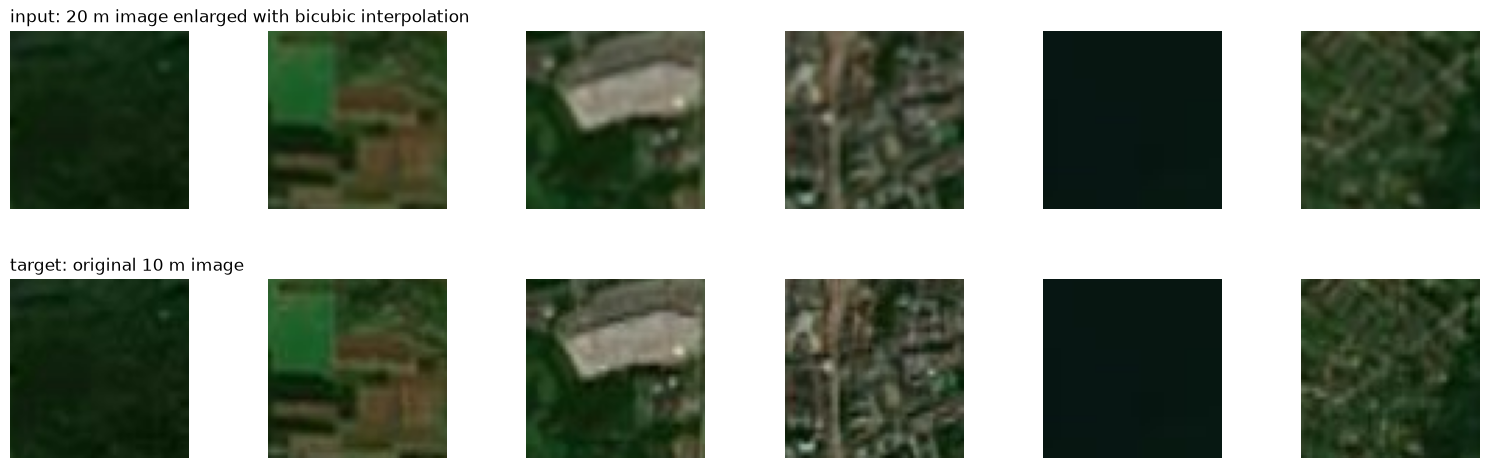

In [6]:
SCALE = 2
PATCH = 64

def to_array(img):
    return np.asarray(img).astype(np.float32) / 255.0

def crop_to_multiple(img, m=8):
    w, h = img.size
    return img.crop((0, 0, w - w % m, h - h % m))

def degrade(img):
    # shrink by SCALE (imitates a coarser sensor) and return the small image and its bicubic enlargement
    w, h = img.size
    low = img.resize((w // SCALE, h // SCALE), Image.BICUBIC)
    return low, low.resize((w, h), Image.BICUBIC)

def random_pairs(img, n, rng, rows=(0.0, 1.0)):
    # n random (blurry input, sharp target) patch pairs taken from the given fraction of image rows
    img = crop_to_multiple(img)
    sharp, blurry = to_array(img), to_array(degrade(img)[1])
    H, W, _ = sharp.shape
    r = rng.integers(int(rows[0] * H), int(rows[1] * H) - PATCH, n)
    c = rng.integers(0, W - PATCH, n)
    xb = np.stack([blurry[i:i + PATCH, j:j + PATCH] for i, j in zip(r, c)])
    yb = np.stack([sharp [i:i + PATCH, j:j + PATCH] for i, j in zip(r, c)])
    return xb, yb

def to_tensor(a):
    return torch.from_numpy(a).permute(0, 3, 1, 2).contiguous()      # (N, H, W, 3) -> (N, 3, H, W)

rng = np.random.default_rng(0)
plan = [("forest", 1500, (0, 1)), ("urban", 1500, (0, 1)), ("ocean", 300, (0, 1)), ("mixed", 2500, (0, 0.8))]
pairs = [random_pairs(scenes[name], n, rng, rows) for name, n, rows in plan]
X_train = to_tensor(np.concatenate([p[0] for p in pairs]))
Y_train = to_tensor(np.concatenate([p[1] for p in pairs]))
xv, yv = random_pairs(scenes["mixed"], 400, rng, rows=(0.8, 1.0))
X_val, Y_val = to_tensor(xv), to_tensor(yv)
print("training pairs:", tuple(X_train.shape), " validation pairs:", tuple(X_val.shape))

fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for col, i in enumerate([10, 700, 1600, 2400, 3100, 4500]):
    axes[0, col].imshow(X_train[i].permute(1, 2, 0)); axes[0, col].axis("off")
    axes[1, col].imshow(Y_train[i].permute(1, 2, 0)); axes[1, col].axis("off")
axes[0, 0].set_title("input: 20 m image enlarged with bicubic interpolation", loc="left")
axes[1, 0].set_title("target: original 10 m image", loc="left")
plt.tight_layout(); plt.show()

### 2.2 A plain convolutional autoencoder

The first model is the textbook autoencoder. The encoder applies convolutions and halves the image size twice with max-pooling, so a 64 x 64 patch becomes a 16 x 16 map with 128 channels (the code, or bottleneck). The decoder mirrors it: it doubles the size twice and applies convolutions until it is back at a 3-channel image, and a sigmoid keeps the output between 0 and 1. The idea is that the bottleneck forces the network to keep only what is essential about the image and to rebuild the rest from what it learned about how such images usually look.

The same class also contains two switches, `skip` and `residual`, which are off for now and are used in next sections. The network is trained with the mean squared error between its output and the sharp target, with the Adam optimiser, for 20 passes over the training patches.

In [7]:
class Autoencoder(nn.Module):
    def __init__(self, skip=False, residual=False):
        super().__init__()
        self.skip, self.residual = skip, residual
        def block(c_in, c_out):
            return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.ReLU(),
                                 nn.Conv2d(c_out, c_out, 3, padding=1), nn.ReLU())
        self.enc1 = block(3, 32)                               # full resolution
        self.enc2 = block(32, 64)                              # 1/2 resolution
        self.bottleneck = block(64, 128)                       # 1/4 resolution
        self.dec2 = block(128 + (64 if skip else 0), 64)
        self.dec1 = block(64 + (32 if skip else 0), 32)
        self.out = nn.Conv2d(32, 3, 3, padding=1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        z = self.bottleneck(F.max_pool2d(e2, 2))
        d = F.interpolate(z, scale_factor=2, mode="nearest")
        d = self.dec2(torch.cat([d, e2], dim=1) if self.skip else d)
        d = F.interpolate(d, scale_factor=2, mode="nearest")
        d = self.dec1(torch.cat([d, e1], dim=1) if self.skip else d)
        d = self.out(d)
        return x + d if self.residual else torch.sigmoid(d)

device = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")

def train(model, epochs=20, batch=64, lr=1e-3):
    model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)      # learning rate decays smoothly to zero
    history = []
    for epoch in range(epochs):
        model.train()
        perm, total = torch.randperm(len(X_train)), 0.0
        for i in range(0, len(perm), batch):
            idx = perm[i:i + batch]
            xb, yb = X_train[idx].to(device), Y_train[idx].to(device)
            loss = F.mse_loss(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(idx)
        sched.step()
        model.eval()
        with torch.no_grad():
            val = F.mse_loss(model(X_val.to(device)), Y_val.to(device)).item()
        history.append((total / len(perm), val))
        if (epoch + 1) % 5 == 0:
            print(f"epoch {epoch + 1:2d}   training MSE {history[-1][0]:.6f}   validation MSE {val:.6f}")
    return np.array(history)

def n_params(model):
    return sum(p.numel() for p in model.parameters())

torch.manual_seed(0)
plain = Autoencoder()
print(f"device: {device}, parameters: {n_params(plain):,}")
hist_plain = train(plain)

device: mps, parameters: 426,307


epoch  5   training MSE 0.001017   validation MSE 0.000557


epoch 10   training MSE 0.000581   validation MSE 0.000294


epoch 15   training MSE 0.000450   validation MSE 0.000235


epoch 20   training MSE 0.000425   validation MSE 0.000223


### 2.3 Does it enhance the resolution?

The trained network is applied to the test image, which it has never seen. The test image is degraded in the same way as the training data, and the output of the network is compared with the true 10 m image. Two measures are used. PSNR is the mean squared error expressed in decibels, so higher is better and +1 dB means about 20 % less squared error. SSIM compares local structure (contrast and edges) and is 1 for identical images. Both are also computed for the bicubic image, which is the result of doing nothing clever.

bicubic interpolation        PSNR  35.96 dB   SSIM 0.9584
plain autoencoder            PSNR  34.53 dB   SSIM 0.9396


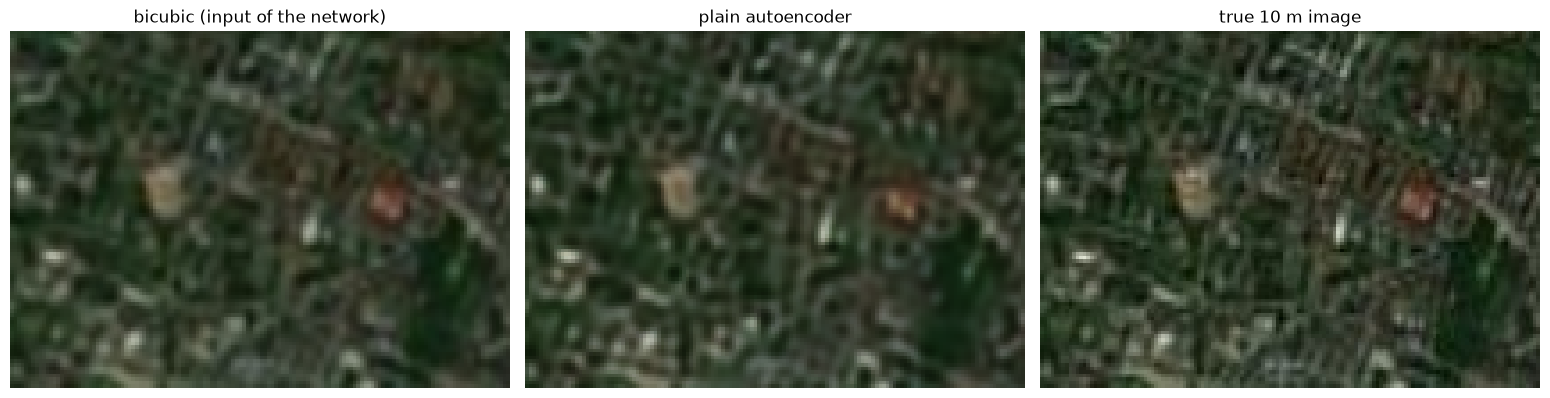

In [8]:
test_hr = crop_to_multiple(scenes["test_scene"])
truth = to_array(test_hr)
bicubic = to_array(degrade(test_hr)[1])

def run(model, img_array):
    # apply the network to a whole image given as an (H, W, 3) array in [0, 1]
    model.eval()
    with torch.no_grad():
        out = model(to_tensor(img_array[None]).to(device)).clamp(0, 1)
    return out[0].permute(1, 2, 0).cpu().numpy()

def psnr(a, b):
    return 10 * np.log10(1.0 / np.mean((a - b) ** 2))

def report(name, img):
    print(f"{name:28s} PSNR {psnr(img, truth):6.2f} dB   SSIM {structural_similarity(img, truth, channel_axis=2, data_range=1.0):.4f}")

def show_zoom(images, titles, box=(170, 270, 840, 980)):
    r0, r1, c0, c1 = box
    fig, axes = plt.subplots(1, len(images), figsize=(5.2 * len(images), 4.2))
    for ax, img, title in zip(axes, images, titles):
        ax.imshow(img[r0:r1, c0:c1], interpolation="nearest"); ax.set_title(title); ax.axis("off")
    plt.tight_layout(); plt.show()

sr_plain = run(plain, bicubic)
report("bicubic interpolation", bicubic)
report("plain autoencoder", sr_plain)
show_zoom([bicubic, sr_plain, truth], ["bicubic (input of the network)", "plain autoencoder", "true 10 m image"])

The answer for the plain autoencoder is no. It reaches 34.53 dB against 35.96 dB for bicubic interpolation, and its SSIM is lower as well, so its output is further from the true image than the blurry input it was given. In the zoom the output is not sharper than the input in any useful way: thin streets are still blurred, and some small objects come out with distorted shapes and colours.

This is a consequence of the architecture, not of too little training. Everything the decoder knows about the image has to pass through the bottleneck, which is four times smaller in each direction than the image. Fine detail is exactly the kind of information that does not survive the two pooling steps, so the network first has to spend its capacity on reproducing the input and has nothing left to improve on it. A bottleneck is useful when the goal is compression or denoising, where throwing detail away is the point. In super-resolution the goal is the opposite.

### 2.4 Making it work better

Two changes to the same network address this directly. Skip connections pass the feature maps of the encoder straight to the decoder layer of the same resolution, so fine detail no longer has to squeeze through the bottleneck (this is the U-Net idea). The residual output makes the network predict only the correction that has to be added to the bicubic image instead of the whole image. The bicubic image is already nearly right, so the network starts from the baseline and can only learn to improve on it; without it, most of the training is spent on learning to copy the input. Everything else stays the same, so the difference between the two models comes from these two switches alone.

parameters: 472,387


epoch  5   training MSE 0.000139   validation MSE 0.000069


epoch 10   training MSE 0.000131   validation MSE 0.000068


epoch 15   training MSE 0.000126   validation MSE 0.000067


epoch 20   training MSE 0.000125   validation MSE 0.000067
validation MSE of the bicubic input itself: 0.000131

bicubic interpolation        PSNR  35.96 dB   SSIM 0.9584
plain autoencoder            PSNR  34.53 dB   SSIM 0.9396
autoencoder + skip + residual PSNR  39.17 dB   SSIM 0.9796


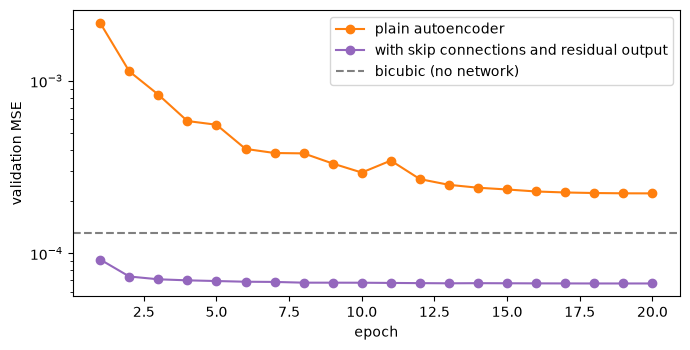

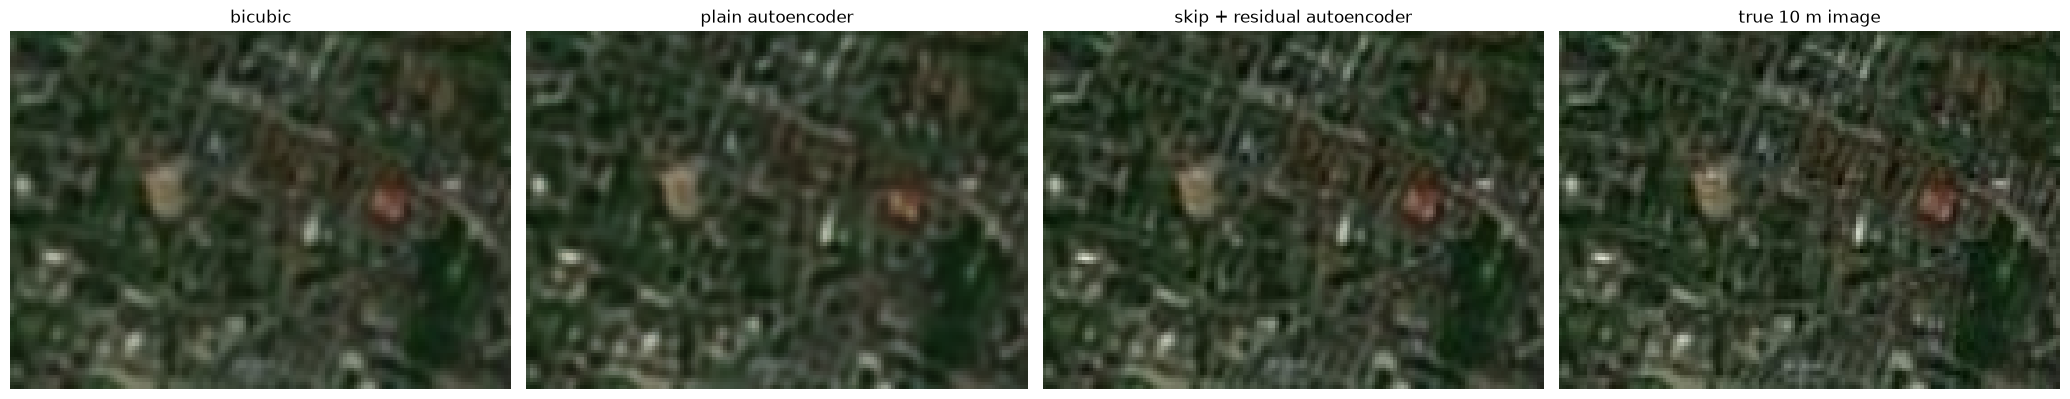

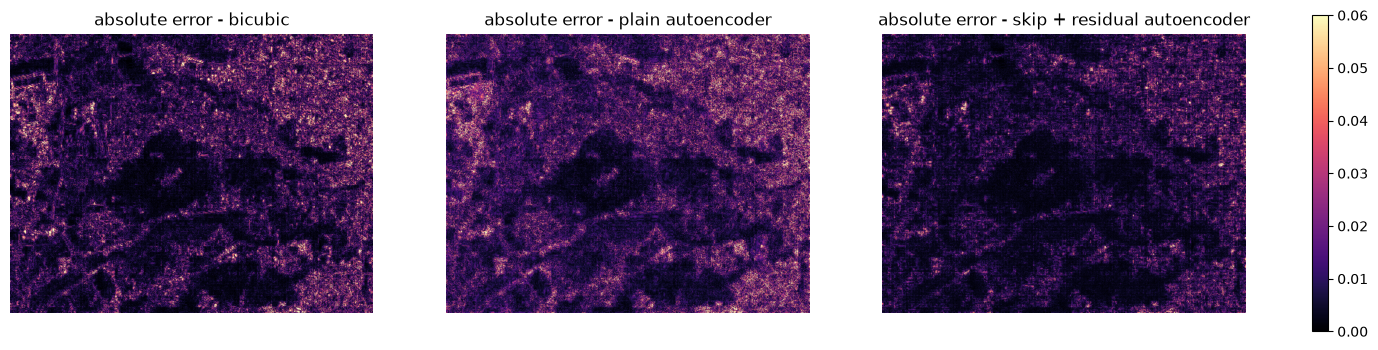

In [9]:
torch.manual_seed(0)
improved = Autoencoder(skip=True, residual=True)
print(f"parameters: {n_params(improved):,}")
hist_improved = train(improved)
print(f"validation MSE of the bicubic input itself: {F.mse_loss(X_val, Y_val).item():.6f}")

sr_improved = run(improved, bicubic)
print()
report("bicubic interpolation", bicubic)
report("plain autoencoder", sr_plain)
report("autoencoder + skip + residual", sr_improved)

fig, ax = plt.subplots(figsize=(7, 3.6))
ep = np.arange(1, len(hist_plain) + 1)
ax.plot(ep, hist_plain[:, 1], "o-", color="tab:orange", label="plain autoencoder")
ax.plot(ep, hist_improved[:, 1], "o-", color="tab:purple", label="with skip connections and residual output")
ax.axhline(F.mse_loss(X_val, Y_val).item(), color="gray", ls="--", label="bicubic (no network)")
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("validation MSE"); ax.legend()
plt.tight_layout(); plt.show()

show_zoom([bicubic, sr_plain, sr_improved, truth],
          ["bicubic", "plain autoencoder", "skip + residual autoencoder", "true 10 m image"])

err = lambda img: np.abs(img - truth).mean(axis=2)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, img, title in zip(axes, [bicubic, sr_plain, sr_improved], ["bicubic", "plain autoencoder", "skip + residual autoencoder"]):
    im = ax.imshow(err(img), cmap="magma", vmin=0, vmax=0.06); ax.set_title(f"absolute error - {title}"); ax.axis("off")
fig.colorbar(im, ax=axes, fraction=0.012); plt.show()

With the two changes the same autoencoder reaches 39.17 dB and an SSIM of 0.9796, which is 3.2 dB better than bicubic interpolation and corresponds to roughly half of its squared error. The validation curve shows the effect of the residual output clearly: the improved model is below the bicubic line already after the first epoch and ends at about half of its error (0.000067 against 0.000131), while the plain one approaches that line from above and never reaches it. In the zoom the streets and building edges are visibly crisper than in the bicubic image and close to the true one, and the error maps show that the errors that remain are concentrated in the built-up areas, where the detail is finest, while forest and fields are reconstructed almost perfectly by any method.

So in this simulated setting the autoencoder does enhance the resolution, provided it is built so that the detail can get past the bottleneck. The last step is to use it the way it would be used in practice: on the original 10 m image, to produce a 5 m image for which no reference exists.

5 m image shrunk back to 10 m, PSNR against the original:  bicubic 48.55 dB | network 54.88 dB
mean absolute difference between the two 5 m images: 0.83 grey levels


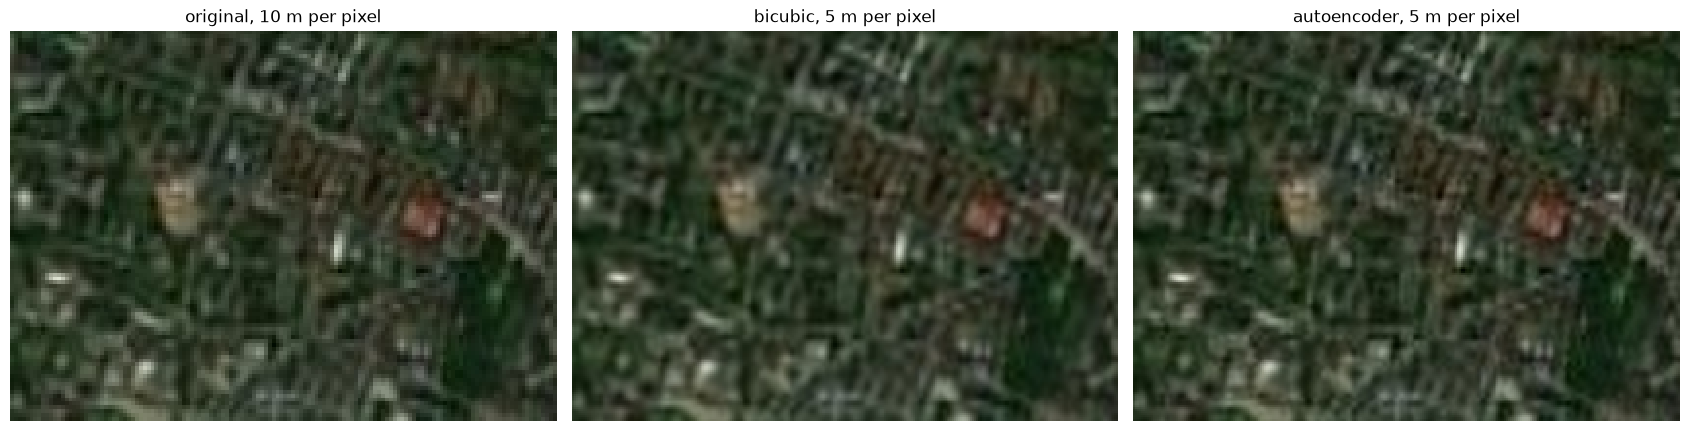

In [10]:
# real use: enlarge the native 10 m test image to 5 m per pixel
native = crop_to_multiple(scenes["test_scene"])
w, h = native.size
up_bicubic = to_array(native.resize((w * SCALE, h * SCALE), Image.BICUBIC))
up_network = run(improved, up_bicubic)

def back_to_10m(img):
    small = Image.fromarray((img * 255).round().astype(np.uint8)).resize((w, h), Image.BICUBIC)
    return to_array(small)

print(f"5 m image shrunk back to 10 m, PSNR against the original:  bicubic {psnr(back_to_10m(up_bicubic), to_array(native)):.2f} dB"
      f" | network {psnr(back_to_10m(up_network), to_array(native)):.2f} dB")
print(f"mean absolute difference between the two 5 m images: {255 * np.abs(up_network - up_bicubic).mean():.2f} grey levels")

r0, r1, c0, c1 = 170, 270, 840, 980
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
axes[0].imshow(to_array(native)[r0:r1, c0:c1], interpolation="nearest"); axes[0].set_title("original, 10 m per pixel")
axes[1].imshow(up_bicubic[2*r0:2*r1, 2*c0:2*c1], interpolation="nearest"); axes[1].set_title("bicubic, 5 m per pixel")
axes[2].imshow(up_network[2*r0:2*r1, 2*c0:2*c1], interpolation="nearest"); axes[2].set_title("autoencoder, 5 m per pixel")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

### 2.5 Conclusions

On the real task the result has to be judged more carefully. The network output at 5 m looks only slightly sharper than the bicubic one, and it is consistent with the measurement: when it is shrunk back to 10 m it matches the original better than the bicubic image does. But the two 5 m images differ by less than one grey level on average, and there is no 5 m reference to say which one is closer to the truth. What the network adds is the kind of edge sharpening it learned at the 20 m to 10 m step. It cant show a car or a single house that the sensor did not record, produces a plausible sharper image, and this matters if the result is used for anything quantitative.

The simulated test is also easier than reality. The low-resolution images were made with one known operation (bicubic shrinking) and the network largely learned to undo that specific blur. A real 20 m sensor differs from a shrunken 10 m image in its optics, noise and sampling, and a network trained on simulated pairs usually loses much of its advantage on real data. The images used here are also JPEG versions of RGB composites, so part of what the network learns to restore is compression artefacts and not ground detail.

Beyond the two changes already made, the things that would help the most are as follows. More and more varied training data, with flips and rotations as augmentation, since the model has seen only four small crops from one region. Real low and high-resolution pairs, or a more realistic simulated degradation with sensor blur and noise, so that the learned mapping transfers to real images. Uncompressed reflectance data with all bands, because Sentinel-2 has 10 m bands that can guide the sharpening of its 20 m bands, which is a much better posed problem than inventing detail from nothing. Working directly on the small image with a learned upsampling layer instead of sharpening a bicubic enlargement, with a deeper residual network. And a perceptual or adversarial loss in place of the mean squared error if the goal is an image that looks sharp, bearing in mind that the mean squared error rewards the safe, slightly blurry average, while those losses produce sharper textures that are partly made up.